<a href="https://colab.research.google.com/github/achyutdipu/EKAXD/blob/main/PINNs_with_EKAXD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PINNs with KAXD

In [ ]:
!pip install deepxde
# If you are using Google Colab, you can uncomment the line above to install the DeepXDE library. Also, change runtime type to GPU for better performance.

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.4/195.4 kB 6.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 11.8 MB/s eta 0:00:00


In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import deepxde as dde
import seaborn as sns
import tensorflow as tf

from scipy.integrate import solve_ivp

No backend selected.
Finding available backend...
Found tensorflow
Using backend: tensorflow
Other supported backends: tensorflow.compat.v1, pytorch, jax, paddle.
paddle supports more examples now and is recommended.


Setting the default backend to "tensorflow". You can change it in the ~/.deepxde/config.json file or export the DDE_BACKEND environment variable. Valid options are: tensorflow.compat.v1, tensorflow, pytorch, jax, paddle (all lowercase)


Enable just-in-time compilation with XLA.



In [12]:
# X_0 = 0.995
E_0 = 45
X_0 = 10
K_0 = 1
A_0 = 26
D_0 = 5.7
# y0 = [S_0, I_0, R_0]  # Initial conditions vector
y0 = [E_0, X_0, D_0, A_0, D_0]

I, alpha, beta_one, r, lambda_, mu, eta, beta_two, theta, k, delta, rho, sigma, z, omega = 1, 0.02, 0.033, 3.8e-5, 0.058, 0.028, 0.0094, 0.00297, 0.032, 1, 0.01, 0.01, 0.0001, 0.003, 0.02
parameters_real = {
  "I": I,
  "alpha": alpha,
  "beta_one": beta_one,
  "r": r,
  "lambda": lambda_,
  "mu": mu,
  "eta": eta,
  "beta_two": beta_two,
  "theta": theta,
  "k": k,
  "delta": delta,
  "rho": rho,
  "sigma": sigma,
  "z": z,
  "omega": omega
}
n_months = 120
noise = 0.025
neurons = 64
layers = 3
activation = "tanh"
num_iterations = 20_000

[[44.96595312 10.09241006  5.7434839  26.26369686  5.67743382]
 [45.0900615  10.84357018  5.7917621  27.00763242  5.80932162]
 [45.17209882 11.83602027  5.78262807 27.6579245   5.70881261]
 [45.30759063 12.56328578  5.83447468 28.29557759  5.7195335 ]
 [45.39377396 13.18410855  5.7918616  28.45578344  5.62017167]
 [45.46441584 14.12623626  6.02061221 30.16061572  5.65331925]
 [45.60198303 14.92052573  5.93994899 30.40218474  5.7253329 ]
 [45.67237888 15.64324514  6.11072638 30.98824378  5.73113907]
 [45.77372458 16.11760284  6.32793863 31.85270858  5.67258624]
 [45.81300532 16.83054079  6.40128553 32.65223665  5.67030051]
 [45.90524385 17.54395776  6.50253193 33.57444272  5.71549777]
 [45.96169828 18.1669377   6.49239377 34.53879106  5.79975673]
 [46.02662021 19.18806729  6.57414827 34.31979052  5.63317576]
 [46.08711683 19.50500734  6.88324567 35.52594256  5.83423761]
 [46.19926241 20.12895782  6.89583996 36.18666473  5.69645823]
 [46.29249    20.59211248  6.92903476 37.06605565  5.65

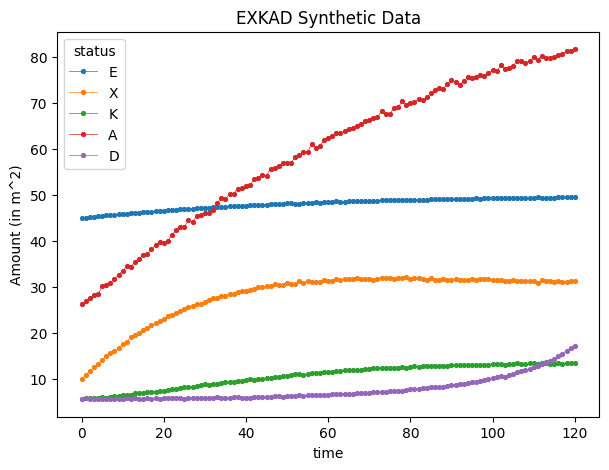

In [13]:
# Generate synthetic data
def generate_data(t_array, y0, args=(I, alpha, beta_one, r, lambda_, mu, eta, beta_two, theta, k, delta, rho, sigma, z, omega)):
  args = I, alpha, beta_one, r, lambda_, mu, eta, beta_two, theta, k, delta, rho, sigma, z, omega
  def func(t, y):
    E, X, K, A, D = y
    dE_dt = I - alpha*E
    dX_dt = beta_one*E + r*D - lambda_*K - mu*X
    dK_dt = eta*X + beta_two*E - theta*K
    dA_dt = k + delta*K - rho*A - sigma*A*D
    dD_dt = sigma*A*D + z*D*D - omega*D
    return [dE_dt, dX_dt, dK_dt, dA_dt, dD_dt]

  t_span = (t_array[0], t_array[-1])
  sol = solve_ivp(func, t_span, y0, t_eval=t_array)
  return sol.y.T

t_train = np.arange(0, n_months + 1)[:, np.newaxis]
y_train = generate_data(np.ravel(t_train), y0)
y_train += np.random.normal(loc=0, scale=y_train.std(axis=0), size=y_train.shape) * noise
print(y_train)
names = list("EXKAD")
data_real = (
  pd.DataFrame(y_train, columns=names, index=t_train.ravel())
  .rename_axis("time")
  .reset_index()
  .melt(id_vars="time", var_name="status", value_name="Amount (in m^2)")
)
print(data_real)
fig, ax = plt.subplots(figsize=(7, 5))
sns.lineplot(
  x="time",
  y="Amount (in m^2)",
  hue="status",
  marker='o',
  linewidth=.5,
  markersize=3,
  markeredgecolor=None,
  data=data_real,
  ax=ax
)
ax.set(title="EXKAD Synthetic Data")
fig.show()

In [14]:
class TransformedVariable(dde.callbacks.Callback):
  def __init__(self, var_list, period=1, filename=None, precision=2, transforms=None):
    super().__init__()
    self.var_list = var_list if isinstance(var_list, list) else [var_list]
    self.period = period
    self.file = open(filename, "w") if filename else None
    self.precision = precision
    self.transforms = transforms
    assert len(var_list) == len(var_list) if transforms else True
  def on_train_begin(self):
    header = "Step      Train loss                        Test loss                         Test metric"
    if self.file is None:
      print(header)
  def on_epoch_end(self):
    if self.transforms is None:
      return super().on_epoch_end()
    step = self.model.train_state.step
    if step % self.period == 0:
      t_vals = [self.transforms[idx](var) for idx, var in enumerate(self.var_list)]
      train_loss = self.model.train_state.loss_train
      test_loss = self.model.train_state.loss_test
      metrics = self.model.train_state.metrics_test
      from deepxde.utils import list_to_str
      str_vars = list_to_str(t_vals, precision=self.precision)
      str_train = list_to_str(train_loss, precision=self.precision)
      str_test = list_to_str(test_loss, precision=self.precision)
      str_metrics = list_to_str(metrics, precision=self.precision)
      output_line = f"{step:<9} {str_train:<33} {str_test:<33} {str_metrics}"
      if self.file:
        self.file.write(str(step) + " " + list_to_str([self.transforms[idx](var).numpy() for idx, var in enumerate(self.model.external_trainable_variables)]) + "\n")
        self.file.flush()
      else:
        print(output_line)
  def on_train_end(self):
    if self.transforms is not None:
      self.value = [self.transforms[idx](var).numpy() for idx, var in enumerate(self.var_list)]
    else:
      self.value = [var.numpy() for var in self.var_list]
    if self.file:
      self.file.close()

Compiling model...
'compile' took 0.012142 s

Training model...

Step      Train loss                                                                                              Test loss                                                                                               Test metric
0         [1.52e-03, 7.91e-05, 4.77e-05, 3.56e-05, 5.15e-05, 2.40e+03, 8.02e+02, 1.20e+02, 3.79e+03, 6.84e+01]    [9.96e-04, 7.84e-05, 3.99e-05, 2.88e-05, 4.85e-05, 2.40e+03, 8.02e+02, 1.20e+02, 3.79e+03, 6.84e+01]    []  
400       [1.02e-02, 6.81e-03, 1.85e-03, 1.13e-02, 1.40e-03, 4.73e+02, 7.11e+01, 6.26e+00, 1.26e+03, 7.51e+00]    [1.16e-03, 7.99e-04, 2.20e-04, 1.25e-03, 1.78e-04, 4.73e+02, 7.11e+01, 6.26e+00, 1.26e+03, 7.51e+00]    []  
800       [1.92e-02, 9.26e-03, 1.58e-03, 2.36e-02, 1.15e-03, 6.50e+01, 3.15e+01, 6.26e+00, 4.95e+02, 7.51e+00]    [2.11e-03, 1.04e-03, 1.83e-04, 2.59e-03, 1.37e-04, 6.50e+01, 3.15e+01, 6.26e+00, 4.95e+02, 7.51e+00]    []  
1200      [3.27e-02, 3.67e-03, 2.38e

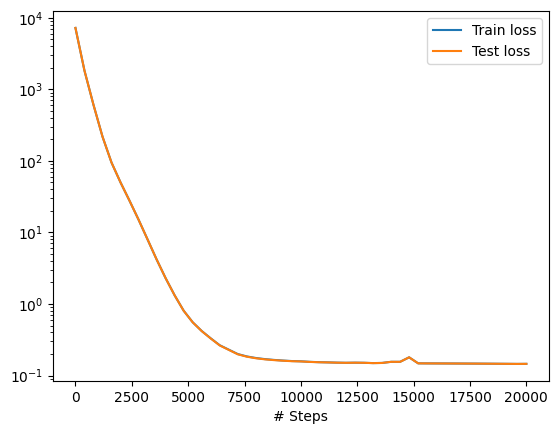

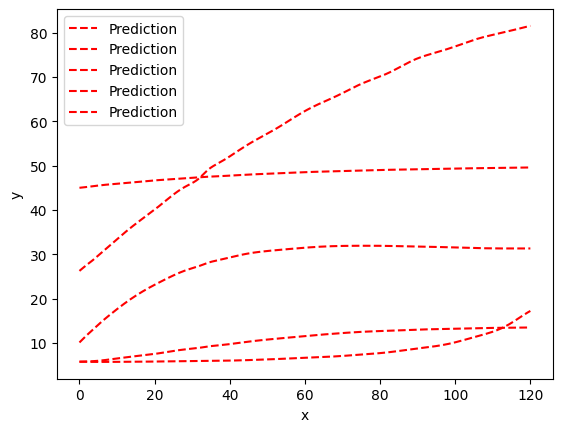

In [15]:
# PINNs
geom = dde.geometry.TimeDomain(t_train[0, 0], t_train[-1, 0])

_I = dde.Variable(0.01)
_alpha = dde.Variable(0.01)
_beta_one = dde.Variable(0.01)
_r = dde.Variable(0.01)
_lambda = dde.Variable(0.01)
_mu = dde.Variable(0.01)
_eta = dde.Variable(0.01)
_beta_two = dde.Variable(0.01)
_theta = dde.Variable(0.01)
_k = dde.Variable(0.01)
_delta = dde.Variable(0.01)
_rho = dde.Variable(0.01)
_sigma = dde.Variable(0.01)
_z = dde.Variable(0.01)
_omega = dde.Variable(0.01)
def helper(var):
  return tf.math.square(tf.math.tanh(var))
def ode(t, y):
  E = y[:, 0:1]
  X = y[:, 1:2]
  K = y[:, 2:3]
  A = y[:, 3:4]
  D = y[:, 4:5]
  dE_dt = dde.grad.jacobian(y, t, i=0)
  dX_dt = dde.grad.jacobian(y, t, i=1)
  dK_dt = dde.grad.jacobian(y, t, i=2)
  dA_dt = dde.grad.jacobian(y, t, i=3)
  dD_dt = dde.grad.jacobian(y, t, i=4)
  I_t = helper(_I)
  alpha_t = helper(_alpha)
  beta_one_t = helper(_beta_one)
  r_t = helper(_r)
  lambda_t = helper(_lambda)
  mu_t = helper(_mu)
  eta_t = helper(_eta)
  beta_two_t = helper(_beta_two)
  theta_t = helper(_theta)
  k_t = helper(_k)
  delta_t = helper(_delta)
  rho_t = helper(_rho)
  sigma_t = helper(_sigma)
  z_t = helper(_z)
  omega_t = helper(tf.math.exp(_omega))
  return [
    dE_dt - (I_t - alpha_t * E),
    dX_dt - (beta_one_t * E + r_t * D - lambda_t * K - mu_t * X),
    dK_dt - (eta_t * X + beta_two_t * E - theta_t * K),
    dA_dt - (k_t + delta_t * K - rho_t * A - sigma_t * A * D),
    dD_dt - (sigma_t * A * D + z_t * D * D - omega_t * D),
  ]
# def ode(t, y):
#   A = y[:, 0:1]
#   D = y[:, 1:2]
#   dA_dt = dde.grad.jacobian(y, t, i=0)
#   dD_dt = dde.grad.jacobian(y, t, i=1)
#   return [
#     dA_dt - (_k - _rho * A - _sigma * A * D),
#     dD_dt - (_sigma * A * D + _z * D * D - _omega * D),
#   ]
observed_E = dde.icbc.PointSetBC(t_train, y_train[:, 0:1], component=0)
observed_X = dde.icbc.PointSetBC(t_train, y_train[:, 1:2], component=1)
observed_K = dde.icbc.PointSetBC(t_train, y_train[:, 2:3], component=2)
observed_A = dde.icbc.PointSetBC(t_train, y_train[:, 3:4], component=3)
observed_D = dde.icbc.PointSetBC(t_train, y_train[:, 4:5], component=4)

data = dde.data.PDE(
  geom,
  ode,
  [observed_E, observed_X, observed_K, observed_A, observed_D],
  num_domain=256,
  num_boundary=2,
  num_test=512,
  anchors=t_train,
)
net = dde.nn.FNN([1] + [neurons] * layers + [5], activation, "Glorot normal")
model = dde.Model(data, net)
model.compile(
  "adam",
  lr=1e-3,
  external_trainable_variables=[_I, _alpha, _beta_one, _r, _lambda, _mu, _eta, _beta_two, _theta, _k, _delta, _rho, _sigma, _z, _omega]
)

variable_filename = f"data_{num_iterations}_steps"
# variable = dde.callbacks.VariableValue(
#   [_k, _rho, _sigma, _z, _omega],
#   period=100,
#   filename=variable_filename
# )
variable = TransformedVariable(
  [_I, _alpha, _beta_one, _r, _lambda, _mu, _eta, _beta_two, _theta, _k, _delta, _rho, _sigma, _z, _omega],
  period=100,
  filename=variable_filename,
  transforms=[
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  helper,
  lambda x: helper(tf.math.exp(x))
  ]
)
losshistory, train_state = model.train(
  iterations=num_iterations,
  display_every=num_iterations // 50,
  callbacks=[variable]
)
dde.saveplot(losshistory, train_state, issave=False, isplot=True)

In [16]:
# Errors
parameter_names = list(parameters_real.keys())
print(variable.value)
errors = (
  pd.DataFrame(
    {"real": parameters_real, "predicted": variable.value},
    index=parameter_names
  )
  .assign(
    relative_error=lambda x: (x["real"] - x["predicted"]).abs() / x["real"]
  )
)
errors

[np.float32(0.9899757), np.float32(0.01978043), np.float32(0.032525007), np.float32(0.0027409734), np.float32(0.06149787), np.float32(0.026547505), np.float32(0.009806226), np.float32(0.0029049346), np.float32(0.03283424), np.float32(0.97094446), np.float32(2.8097447e-05), np.float32(0.0072619393), np.float32(0.0001599379), np.float32(0.002542904), np.float32(0.020073958)]


,real,predicted,relative_error
I,1.000000,0.989976,0.010024
alpha,0.020000,0.019780,0.010979
beta_one,0.033000,0.032525,0.014394
r,0.000038,0.002741,71.130878
lambda,0.058000,0.061498,0.060308
mu,0.028000,0.026548,0.051875
eta,0.009400,0.009806,0.043216
beta_two,0.002970,0.002905,0.021908
theta,0.032000,0.032834,0.026070
k,1.000000,0.970944,0.029056


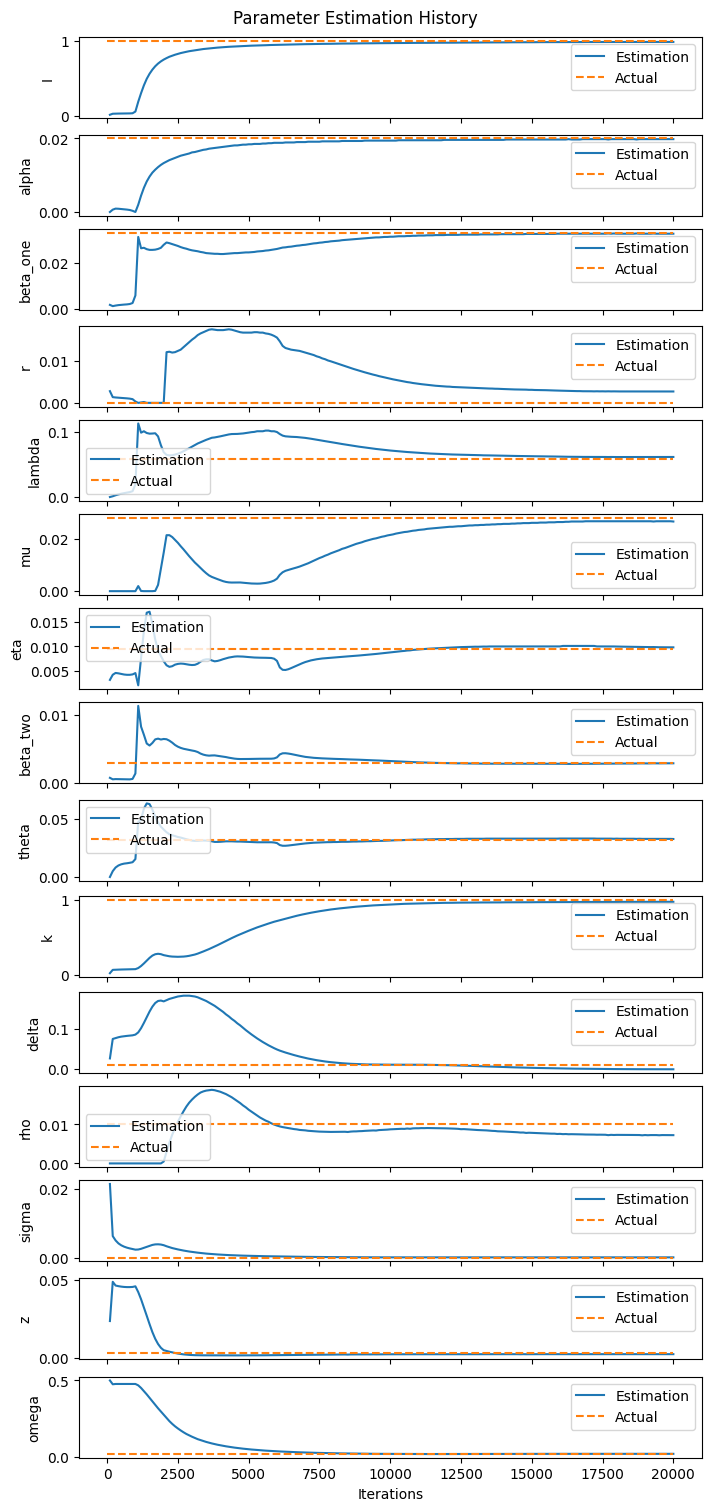

In [17]:
# Learning History
lines = open(variable_filename, "r").readlines()
raw_parameters_pred_history = np.array(
  [
    np.fromstring(
      min(re.findall(re.escape("[") + "(.*?)" + re.escape("]"), line), key=len),
      sep=",",
    ) for line in lines
  ]
)
iterations = [int(re.findall("^[0-9]+", line)[0]) for line in lines]
parameters_pred_history = {
  name: raw_parameters_pred_history[:, i]
  for i, name in enumerate(parameters_real.keys())
}

n_callbacks, n_variables = raw_parameters_pred_history.shape
fig, axes = plt.subplots(nrows=n_variables, sharex=True, figsize=(7, 15), layout="constrained")
for ax, (parameter, parameter_value) in zip(axes, parameters_real.items()):
  ax.plot(iterations, parameters_pred_history[parameter] , "-", label="Estimation")
  ax.hlines(parameter_value, xmin=0, xmax=num_iterations, linestyles="dashed",  color=sns.color_palette()[1], label="Actual")
  ax.set_ylabel(parameter)
  ax.legend()
ax.set_xlabel("Iterations")
fig.suptitle("Parameter Estimation History")
fig.savefig("EKAXD Parameter Estimation History.jpg", dpi=300, bbox_inches="tight")
fig.show()

131
(131,)
(131,)
     time         status  Amount (in specified units)
0       0  E (Predicted)                    45.000000
1       1  E (Predicted)                    45.099007
2       2  E (Predicted)                    45.196053
3       3  E (Predicted)                    45.291178
4       4  E (Predicted)                    45.384421
..    ...            ...                          ...
650   126  D (Predicted)                    23.034190
651   127  D (Predicted)                    24.454243
652   128  D (Predicted)                    26.095362
653   129  D (Predicted)                    27.999426
654   130  D (Predicted)                    30.212787

[655 rows x 3 columns]
      time         status  Amount (in specified units)
0        0              E                    45.015619
1        1              E                    45.135319
2        2              E                    45.173362
3        3              E                    45.281676
4        4              E          

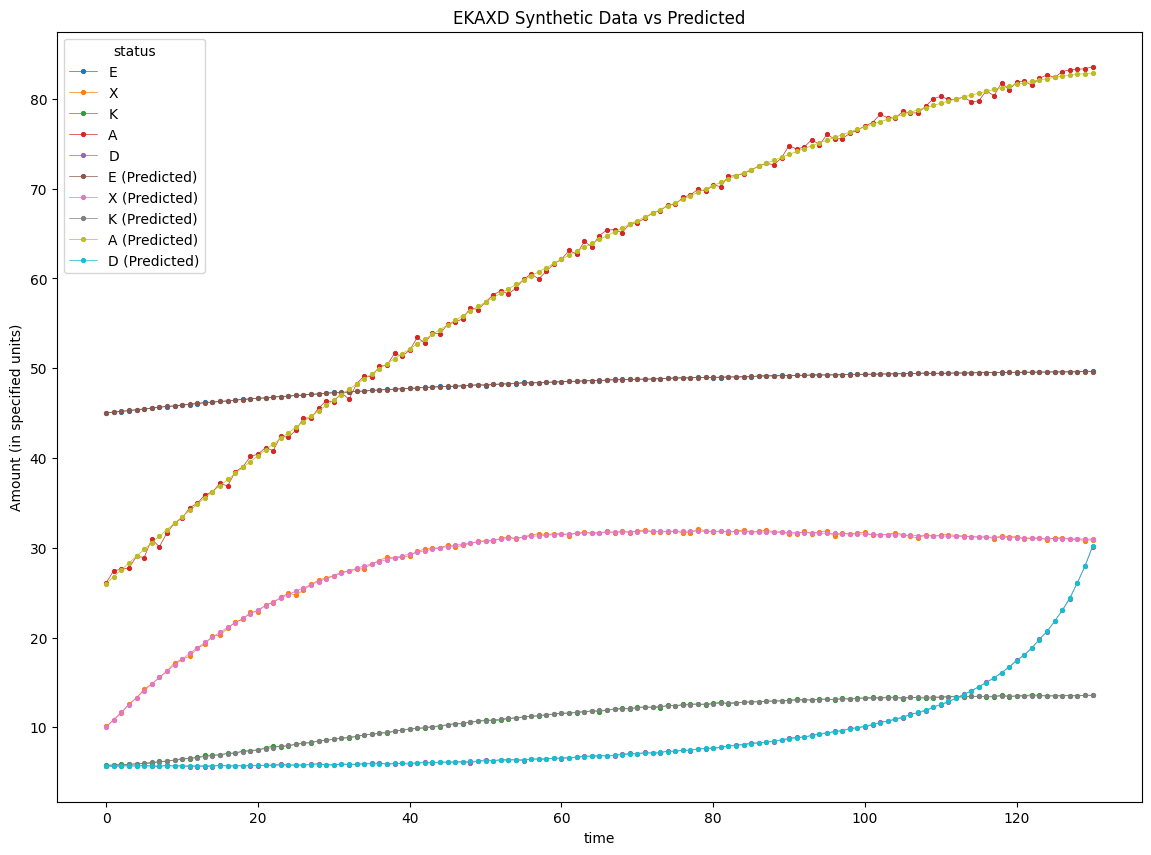

In [18]:
pred_values = [v[-1] for v in parameters_pred_history.values()]
pred_names = [i+" (Predicted)" for i in names]
t_train = np.arange(0, 131)
y_pred = generate_data(np.ravel(t_train), y0, args=tuple(pred_values))
y_train = generate_data(np.ravel(t_train), y0) + np.random.normal(loc=0, scale=y_train.std(axis=0), size=y_pred.shape) * noise
print(y_pred.shape[0])
print(t_train.shape)
t_pred = t_train[:y_pred.shape[0]]
print(t_pred.shape)
data_pred = (
  pd.DataFrame(y_pred, columns=pred_names, index=t_pred.ravel())
  .rename_axis("time")
  .reset_index()
  .melt(id_vars="time", var_name="status", value_name="Amount (in specified units)")
)
data_real = (
  pd.DataFrame(y_train, columns=names, index=t_train.ravel())
  .rename_axis("time")
  .reset_index()
  .melt(id_vars="time", var_name="status", value_name="Amount (in specified units)")
)
print(data_pred)
data_total = pd.concat([data_real, data_pred], ignore_index=True)
print(data_total)
residuals = y_train-y_pred
ssres = np.pow(residuals, 2).sum()
mse = ssres/len(residuals)
rmse = np.sqrt(mse)
sstot = np.pow(np.abs(y_train-y_train.mean()), 2).sum()
r2 = 1-ssres/sstot
mape = (np.abs(residuals)/y_train).sum()*100/len(residuals)
print(mse, rmse, r2, mape)
no_noise = generate_data(np.ravel(t_train), y0)
residuals_nonoise = no_noise-y_pred
ssres_nonoise = np.pow(residuals_nonoise, 2).sum()
mse_nonoise = ssres_nonoise/len(residuals_nonoise)
rmse_nonoise = np.sqrt(mse_nonoise)
sstot_nonoise = np.pow(np.abs(no_noise-no_noise.mean()), 2).sum()
r2_nonoise = 1-ssres_nonoise/sstot_nonoise
mape_nonoise = (np.abs(residuals_nonoise)/no_noise).sum()*100/len(residuals_nonoise)
print(mse_nonoise, rmse_nonoise, r2_nonoise, mape_nonoise)
normrmse = rmse/np.sum(np.square(y_train))
normrmse_nonoise = rmse_nonoise/np.sum(np.square(no_noise))
print(normrmse)
print(normrmse_nonoise)
fig, ax = plt.subplots(figsize=(14, 10))
sns.lineplot(
  x="time",
  y="Amount (in specified units)",
  hue="status",
  marker='o',
  linewidth=.5,
  markersize=3,
  markeredgecolor=None,
  data=data_total,
  ax=ax
)
ax.set(title="EKAXD Synthetic Data vs Predicted")
fig.savefig("EKAXD Synthetic Data vs Predicted.jpg", dpi=300, bbox_inches="tight")
fig.show()